# Official fast.ai course22 original 07 — Colab adaptation

Original: [07-how-random-forests-really-work.ipynb](https://github.com/fastai/course22/blob/230390584ba5b990e20487d68681a9ec5b258eff/clean/07-how-random-forests-really-work.ipynb)

Pinned source commit: `230390584ba5b990e20487d68681a9ec5b258eff`. Source SHA256: `89996bf458d724da608aa8fa96916ccfaf4d6692cc76fabe450f406627613943`.

This additional notebook preserves the full original computational experiments. Existing independently written companions 00–07 remain separate. Set QUICK_RUN=False; run every code cell. Source notebooks and authorship belong to Jeremy Howard and fast.ai. No separate course22 repository license was found at the pinned commit; no fastbook license is applied to these files.

- Original Kaggle train/test data sourced from pinned public teaching copies. All891/418 passengers, column names, values and Name/Ticket/Cabin features verified against a second independent competition mirror; training values also equal the DataScienceDojo copy. No Kaggle provider checksum/terms acceptance/account score is claimed. Test labels remain unavailable.
- All source baselines, split searches, Gini, trees and100*.75 bagging/RF preserved. Graphviz DOT/SVG saved when available; equivalent sklearn tree plots are the documented fallback if dot is absent.

Public publication and competition submission have not been performed. Saved predictions are learning artifacts; the 418 Titanic test targets are unavailable. Original conceptual prompts/headings are retained below.


In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '03_fastai', 'fastai', '24_original_07_random_forests.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)
if IN_COLAB:
    from packaging.requirements import Requirement
    import importlib.metadata as _metadata, subprocess
    _missing = []
    for _spec in ['seaborn>=0.13,<1', 'graphviz>=0.20,<1']:
        _requirement = Requirement(_spec)
        try: _version = _metadata.version(_requirement.name)
        except _metadata.PackageNotFoundError: _version = None
        if _version is None or _version not in _requirement.specifier: _missing.append(_spec)
    if _missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *_missing])

Exercise folder: /content/HaiLong_Colab_Exercises/03_fastai
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/03_fastai/results


In [2]:
# Full-source execution and durable evidence helpers (Colab adaptation).
import hashlib, json, shutil, urllib.request
from datetime import datetime, timezone
if QUICK_RUN or os.environ.get('COURSE_SMOKE') == '1':
    raise ValueError('These original notebooks require full mode: set QUICK_RUN=False.')
RESULTS = COLAB_CONTEXT['folder'] / 'results' / Path(COLAB_CONTEXT['run']['notebook']).stem
MODELS = COLAB_CONTEXT['folder'] / 'models' / Path(COLAB_CONTEXT['run']['notebook']).stem
WORK = COLAB_CONTEXT['folder'] / 'data' / Path(COLAB_CONTEXT['run']['notebook']).stem
for directory in [RESULTS, MODELS, WORK]: directory.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)

def record_stage(stage, **evidence):
    target = RESULTS / 'stage_evidence.json'
    started = COLAB_CONTEXT['run']['started_utc']
    data = json.loads(target.read_text(encoding='utf-8')) if target.is_file() else {}
    if data.get('run_started_utc') != started:
        data = {'notebook': COLAB_CONTEXT['run']['notebook'], 'run_started_utc': started, 'stages': {}}
    data['stages'][stage] = {'recorded_utc': datetime.now(timezone.utc).isoformat(), **evidence}
    data.update(quick_run=False, status='observed_stage_outputs', provider_course_completion_claimed=False,
                learner_personal_reflection_complete=False)
    temporary = target.with_suffix('.writing')
    temporary.write_text(json.dumps(data, indent=2, default=str), encoding='utf-8')
    temporary.replace(target)

def verified_download(url, target, sha256):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if not target.is_file():
        temporary = target.with_name(target.name + '.download')
        with urllib.request.urlopen(url, timeout=120) as response, temporary.open('wb') as out:
            shutil.copyfileobj(response, out)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != sha256:
            raise ValueError('Source download checksum mismatch: ' + url)
        temporary.replace(target)
    if hashlib.sha256(target.read_bytes()).hexdigest() != sha256:
        raise ValueError('Existing source file differs from the pinned original: ' + str(target))
    return target

def save_plot(figure, name):
    if hasattr(figure, 'write_html'):
        figure.write_html(RESULTS / (name + '.html'), include_plotlyjs=True)
    elif hasattr(figure, 'savefig'):
        figure.savefig(RESULTS / (name + '.png'), dpi=150, bbox_inches='tight')
    return figure

record_stage('full_mode_setup', execution_location='hosted_colab' if IN_COLAB else 'local_validation',
             original_exercises_verified_complete=False)

## Evidence required for the original exercises

- Execute every nonempty original code cell top to bottom in hosted Colab; retain outputs and execution records.
- QUICK_RUN=False. Original experiment data coverage, epochs and learning rates are preserved.
- Original source attribution and the per-cell provenance map distinguish original exercises from companions.
- Save full notebook outputs and actual stage/checkpoint/artifact evidence in Drive.
- No provider badge, external publishing, competition submission or personal authorship is certified by execution.
- Retain sex/fare baselines, weighted standard-deviation split scores and widgets, Age and per-sex best split searches, two source trees/diagrams/Gini,100 manual75%-size bootstrap trees and100-tree RF, validation MAE, feature importance, and418-row tree/RF test CSVs.


## Introduction

In [3]:
from fastai.imports import *
np.set_printoptions(linewidth=130)

## Data preprocessing

In [4]:
# Exact public teaching copies of the original Kaggle competition files.
# No credentials, test labels, rule acceptance, or competition submission are inferred.
path = COLAB_CONTEXT['folder'] / 'data' / 'titanic_original'
_titanic_sources = [{'file': 'train.csv', 'url': 'https://raw.githubusercontent.com/minsuk-heo/kaggle-titanic/96c14e776090f7919d15064ed73e3b2788b4288c/input/train.csv', 'sha256': '7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f', 'rows': 891, 'columns': ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], 'all_values_equal_independent_dsindy_pin': True, 'all_values_equal_datadojo': True}, {'file': 'test.csv', 'url': 'https://raw.githubusercontent.com/minsuk-heo/kaggle-titanic/96c14e776090f7919d15064ed73e3b2788b4288c/input/test.csv', 'sha256': '56023b9948236f3c7a1c9448fcf418b283e109ef177fa8c7e069158dd7dd52b2', 'rows': 418, 'columns': ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], 'all_values_equal_independent_dsindy_pin': True}]
for _source in _titanic_sources:
    verified_download(_source['url'], path / _source['file'], _source['sha256'])
import pandas as pd
_train = pd.read_csv(path / 'train.csv')
_test = pd.read_csv(path / 'test.csv')
assert _train.shape == (891, 12) and _test.shape == (418, 11)
assert _train.PassengerId.tolist() == list(range(1, 892))
assert _test.PassengerId.tolist() == list(range(892, 1310))
assert 'Survived' not in _test and int(_train.Survived.sum()) == 342
record_stage('original_titanic_inputs', sources=_titanic_sources, train_rows=891, test_rows=418,
             held_out_test_labels_available=False, competition_submission_performed=False)
df = pd.read_csv(path/'train.csv')
tst_df = pd.read_csv(path/'test.csv')
modes = df.mode().iloc[0]

In [5]:
def proc_data(df):
    df['Fare'] = df.Fare.fillna(0)
    df.fillna(modes, inplace=True)
    df['LogFare'] = np.log1p(df['Fare'])
    df['Embarked'] = pd.Categorical(df.Embarked)
    df['Sex'] = pd.Categorical(df.Sex)

proc_data(df)
proc_data(tst_df)

In [6]:
cats=["Sex","Embarked"]
conts=['Age', 'SibSp', 'Parch', 'LogFare',"Pclass"]
dep="Survived"

In [7]:
df.Sex.head()

,Sex
0,male
1,female
2,female
3,female
4,male


In [8]:
df.Sex.cat.codes.head()

,0
0,1
1,0
2,0
3,0
4,1


## Binary splits

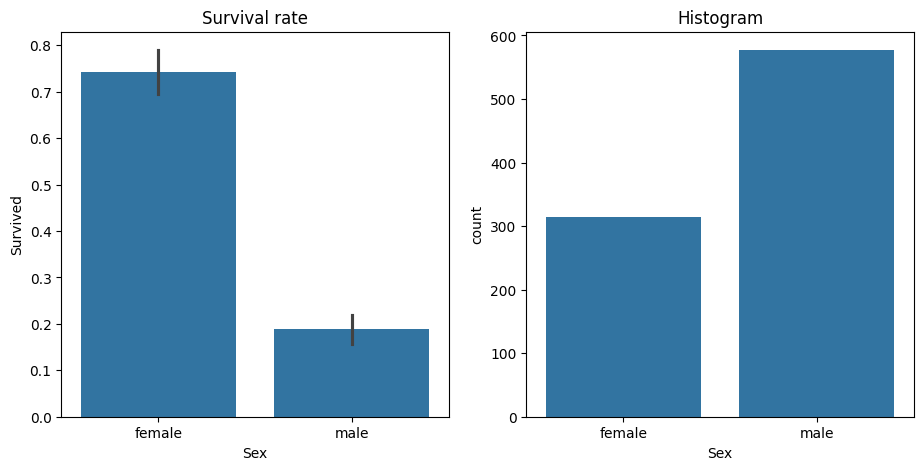

In [9]:
import seaborn as sns

fig,axs = plt.subplots(1,2, figsize=(11,5))
sns.barplot(data=df, y=dep, x="Sex", ax=axs[0]).set(title="Survival rate")
sns.countplot(data=df, x="Sex", ax=axs[1]).set(title="Histogram");

In [10]:
from numpy import random
from sklearn.model_selection import train_test_split

random.seed(42)
trn_df,val_df = train_test_split(df, test_size=0.25)
trn_df[cats] = trn_df[cats].apply(lambda x: x.cat.codes)
val_df[cats] = val_df[cats].apply(lambda x: x.cat.codes)

In [11]:
def xs_y(df):
    xs = df[cats+conts].copy()
    return xs,df[dep] if dep in df else None

trn_xs,trn_y = xs_y(trn_df)
val_xs,val_y = xs_y(val_df)

In [12]:
preds = val_xs.Sex==0

In [13]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(val_y, preds)

0.21524663677130046

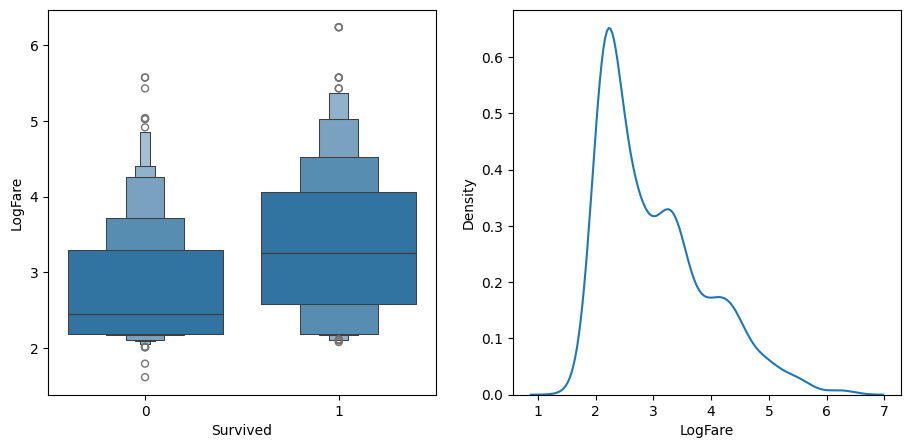

In [14]:
df_fare = trn_df[trn_df.LogFare>0]
fig,axs = plt.subplots(1,2, figsize=(11,5))
sns.boxenplot(data=df_fare, x=dep, y="LogFare", ax=axs[0])
sns.kdeplot(data=df_fare, x="LogFare", ax=axs[1]);

In [15]:
preds = val_xs.LogFare>2.7

In [16]:
mean_absolute_error(val_y, preds)

0.336322869955157

In [17]:
def _side_score(side, y):
    tot = side.sum()
    if tot<=1: return 0
    return y[side].std()*tot

In [18]:
    
def score(col, y, split):
    lhs = col<=split
    return (_side_score(lhs,y) + _side_score(~lhs,y))/len(y)

In [19]:
score(trn_xs["Sex"], trn_y, 0.5)

np.float64(0.4078753098206398)

In [20]:
score(trn_xs["LogFare"], trn_y, 2.7)

np.float64(0.4718087395209973)

In [21]:
def iscore(nm, split):
    col = trn_xs[nm]
    return score(col, trn_y, split)

from ipywidgets import interact
interact(nm=conts, split=15.5)(iscore);

interactive(children=(Dropdown(description='nm', options=('Age', 'SibSp', 'Parch', 'LogFare', 'Pclass'), value…

In [22]:
interact(nm=cats, split=2)(iscore);

interactive(children=(Dropdown(description='nm', options=('Sex', 'Embarked'), value='Sex'), IntSlider(value=2,…

In [23]:
nm = "Age"
col = trn_xs[nm]
unq = col.unique()
unq.sort()
unq

array([ 0.42,  0.67,  0.75,  0.83,  0.92,  1.  ,  2.  ,  3.  ,  4.  ,  5.  ,  6.  ,  7.  ,  8.  ,  9.  , 10.  , 11.  , 12.  ,
       13.  , 14.  , 14.5 , 15.  , 16.  , 17.  , 18.  , 19.  , 20.  , 21.  , 22.  , 23.  , 24.  , 24.5 , 25.  , 26.  , 27.  ,
       28.  , 28.5 , 29.  , 30.  , 31.  , 32.  , 32.5 , 33.  , 34.  , 34.5 , 35.  , 36.  , 36.5 , 37.  , 38.  , 39.  , 40.  ,
       40.5 , 41.  , 42.  , 43.  , 44.  , 45.  , 45.5 , 46.  , 47.  , 48.  , 49.  , 50.  , 51.  , 52.  , 53.  , 54.  , 55.  ,
       55.5 , 56.  , 57.  , 58.  , 59.  , 60.  , 61.  , 62.  , 64.  , 65.  , 70.  , 70.5 , 74.  , 80.  ])

In [24]:
scores = np.array([score(col, trn_y, o) for o in unq if not np.isnan(o)])
unq[scores.argmin()]

np.float64(6.0)

In [25]:
def min_col(df, nm):
    col,y = df[nm],df[dep]
    unq = col.dropna().unique()
    scores = np.array([score(col, y, o) for o in unq if not np.isnan(o)])
    idx = scores.argmin()
    return unq[idx],scores[idx]

min_col(trn_df, "Age")

(np.float64(6.0), np.float64(0.47831671750899085))

In [26]:
cols = cats+conts
{o:min_col(trn_df, o) for o in cols}

{'Sex': (np.int8(0), np.float64(0.4078753098206398)),
 'Embarked': (np.int8(0), np.float64(0.478833425731479)),
 'Age': (np.float64(6.0), np.float64(0.47831671750899085)),
 'SibSp': (np.int64(4), np.float64(0.4783740258817423)),
 'Parch': (np.int64(0), np.float64(0.4805296527841601)),
 'LogFare': (np.float64(2.4390808375825834), np.float64(0.4620823937736595)),
 'Pclass': (np.int64(2), np.float64(0.4604826188580666))}

## Creating a decision tree

In [27]:
cols.remove("Sex")
ismale = trn_df.Sex==1
males,females = trn_df[ismale],trn_df[~ismale]

In [28]:
{o:min_col(males, o) for o in cols}

{'Embarked': (np.int8(0), np.float64(0.387558187041091)),
 'Age': (np.float64(6.0), np.float64(0.37398283710105873)),
 'SibSp': (np.int64(4), np.float64(0.38758642275862637)),
 'Parch': (np.int64(0), np.float64(0.3874704821461953)),
 'LogFare': (np.float64(2.803360380906535), np.float64(0.38048562317581447)),
 'Pclass': (np.int64(1), np.float64(0.3815544200436083))}

In [29]:
{o:min_col(females, o) for o in cols}

{'Embarked': (np.int8(0), np.float64(0.4295252982857326)),
 'Age': (np.float64(50.0), np.float64(0.4225927658431646)),
 'SibSp': (np.int64(4), np.float64(0.42319212059713585)),
 'Parch': (np.int64(3), np.float64(0.4193314500446157)),
 'LogFare': (np.float64(4.256321678298823), np.float64(0.413505983329114)),
 'Pclass': (np.int64(2), np.float64(0.3335388911567602))}

In [30]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz

m = DecisionTreeClassifier(max_leaf_nodes=4).fit(trn_xs, trn_y);

In [31]:
# Original Graphviz diagrams; matplotlib fallback if the host lacks the dot binary.
import graphviz, shutil
def draw_tree(t, df, size=10, ratio=0.6, precision=2, **kwargs):
    s=export_graphviz(t, out_file=None, feature_names=df.columns, filled=True, rounded=True,
                     special_characters=True, rotate=False, precision=precision, **kwargs)
    target = RESULTS / f'tree_{t.get_n_leaves()}_leaves'
    target.with_suffix('.dot').write_text(s, encoding='utf-8')
    if shutil.which('dot'):
        diagram = graphviz.Source(re.sub('Tree {', f'Tree {{ size={size}; ratio={ratio}', s))
        diagram.render(str(target), format='svg', cleanup=True)
        return diagram
    from sklearn.tree import plot_tree
    fig, ax = plt.subplots(figsize=(size, max(5, size*ratio)))
    plot_tree(t, feature_names=list(df.columns), filled=True, rounded=True, precision=precision, ax=ax, **kwargs)
    save_plot(fig, target.name)
    return fig

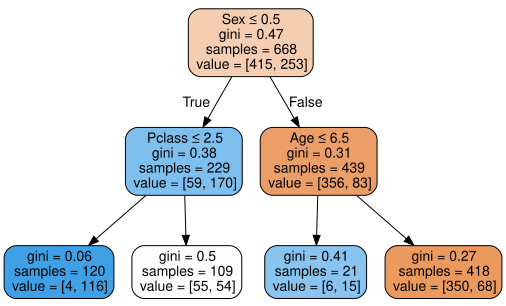

In [32]:
draw_tree(m, trn_xs, size=10)

In [33]:
def gini(cond):
    act = df.loc[cond, dep]
    return 1 - act.mean()**2 - (1-act).mean()**2

In [34]:
gini(df.Sex=='female'), gini(df.Sex=='male')

(np.float64(0.3828350034484158), np.float64(0.3064437162277842))

In [35]:
mean_absolute_error(val_y, m.predict(val_xs))

0.2242152466367713

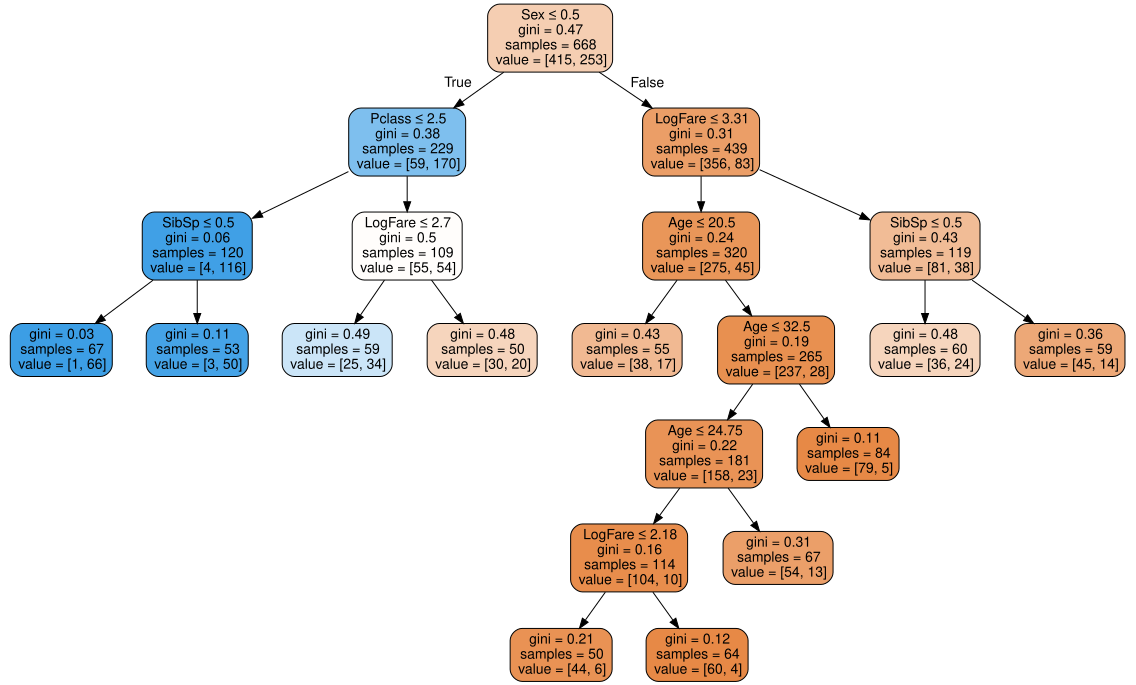

In [36]:
m = DecisionTreeClassifier(min_samples_leaf=50)
m.fit(trn_xs, trn_y)
draw_tree(m, trn_xs, size=25)

In [37]:
mean_absolute_error(val_y, m.predict(val_xs))

0.18385650224215247

In [38]:
tst_df[cats] = tst_df[cats].apply(lambda x: x.cat.codes)
tst_xs,_ = xs_y(tst_df)

def subm(preds, suff):
    tst_df['Survived'] = preds
    sub_df = tst_df[['PassengerId','Survived']]
    sub_df.to_csv(RESULTS / f'sub-{suff}.csv', index=False)

subm(m.predict(tst_xs), 'tree')

In [39]:
df.Embarked.head()

,Embarked
0,S
1,C
2,S
3,S
4,S


In [40]:
df.Embarked.cat.codes.head()

,0
0,2
1,0
2,2
3,2
4,2


## The random forest

In [41]:
def get_tree(prop=0.75):
    n = len(trn_y)
    idxs = random.choice(n, int(n*prop))
    return DecisionTreeClassifier(min_samples_leaf=5).fit(trn_xs.iloc[idxs], trn_y.iloc[idxs])

In [42]:
trees = [get_tree() for t in range(100)]

In [43]:
all_probs = [t.predict(val_xs) for t in trees]
avg_probs = np.stack(all_probs).mean(0)

mean_absolute_error(val_y, avg_probs)

record_stage('manual_bagging_validation', trees=len(trees), bootstrap_fraction=.75, min_samples_leaf=5, validation_rows=len(val_y), mean_absolute_error=float(mean_absolute_error(val_y, avg_probs)))

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(100, min_samples_leaf=5)
rf.fit(trn_xs, trn_y);
mean_absolute_error(val_y, rf.predict(val_xs))

0.18834080717488788

In [45]:
subm(rf.predict(tst_xs), 'rf')

record_stage('random_forest_and_test_exports', trees=100, min_samples_leaf=5, validation_rows=len(val_y), mean_absolute_error=float(mean_absolute_error(val_y, rf.predict(val_xs))), test_rows=len(tst_df), csvs=['sub-tree.csv','sub-rf.csv'], submitted=False)

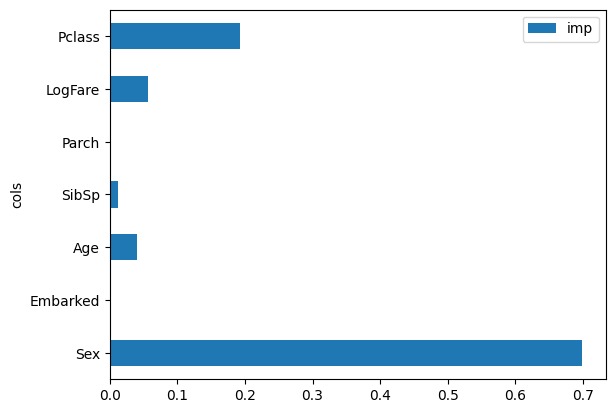

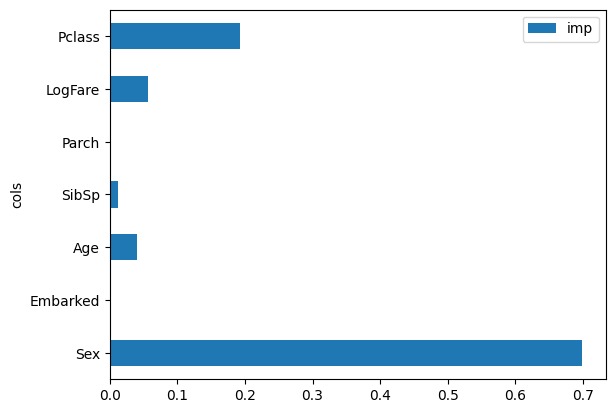

In [46]:
pd.DataFrame(dict(cols=trn_xs.columns, imp=m.feature_importances_)).plot('cols', 'imp', 'barh');

save_plot(plt.gcf(), 'larger_tree_feature_importance')

## Conclusion

In [47]:
record_stage('reached_final_cell', all_previous_cells_independently_verified=False)
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [48]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "03_fastai/24_original_07_random_forests.ipynb", "source_sha256": "e09254b004a28e81b2fb6a970004df2cd95920fbd300d673d393d1fc9d43ee43", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "colab_runtime.py": "e11bedb13e1bd71a71c01cc49e558d05c89b057259fe52e64301d0c4d626a140", "course_persistence.py": "f14f7282d4b1e718b01858a61a2dca8b60f5135ba9971fc7923c50bf12cca3d2"}, "persistent_course_